In [1]:
import pandas as pd

url = "https://www.statlearning.com/s/Advertising.csv"

df = pd.read_csv(url, index_col=0)

print(df.head())
print(df.shape)

      TV  radio  newspaper  sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9
(200, 4)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
print("First 5 Rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:", df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

First 5 Rows:


,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9



Dataset Shape: (200, 4)

Column Names: ['TV', 'radio', 'newspaper', 'sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 7.8 KB

Statistical Summary:


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000



Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Duplicate Rows: 0

Data Types:
TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object


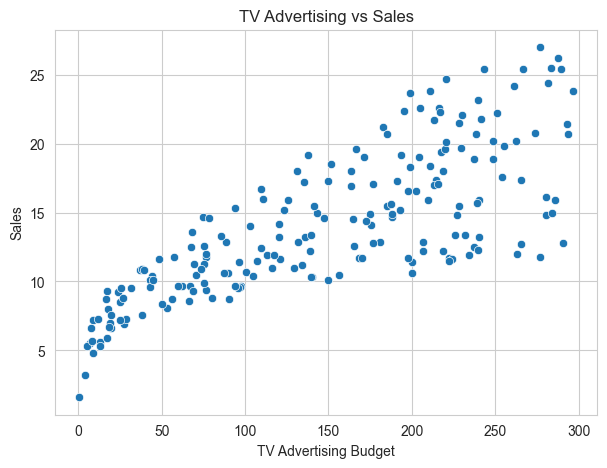

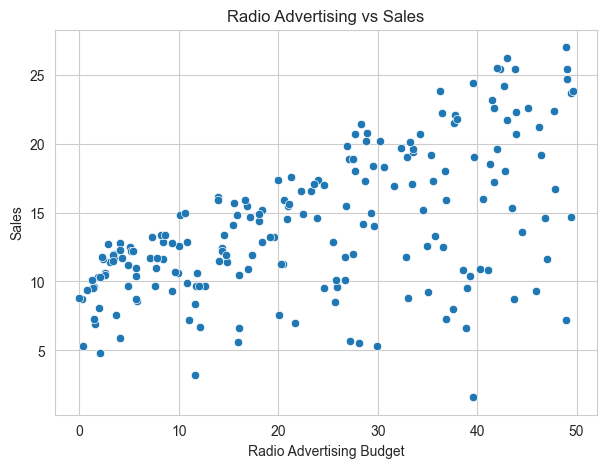

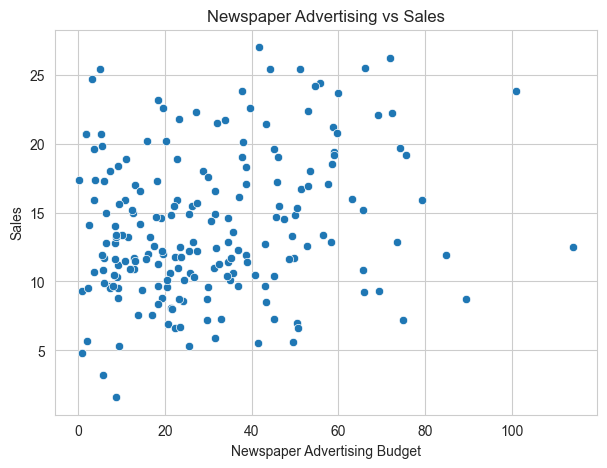

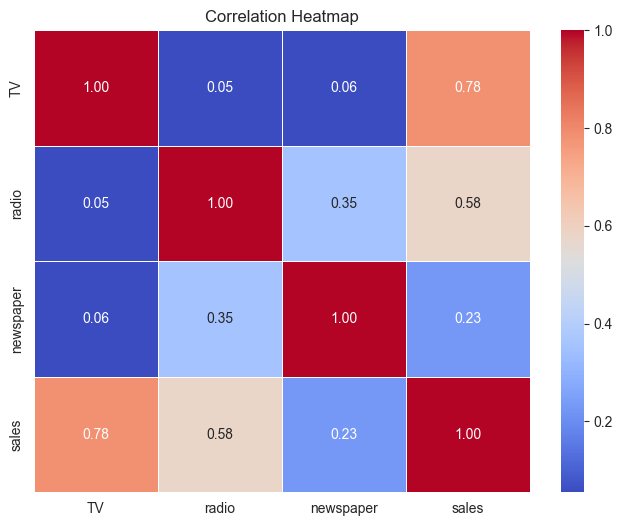

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='TV', y='sales')
plt.title('TV Advertising vs Sales')
plt.xlabel('TV Advertising Budget')
plt.ylabel('Sales')
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='radio', y='sales')
plt.title('Radio Advertising vs Sales')
plt.xlabel('Radio Advertising Budget')
plt.ylabel('Sales')
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='newspaper', y='sales')
plt.title('Newspaper Advertising vs Sales')
plt.xlabel('Newspaper Advertising Budget')
plt.ylabel('Sales')
plt.show()

plt.figure(figsize=(8, 6))
correlation = df.corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap')
plt.show()

In [7]:
X = df[['TV', 'radio', 'newspaper']]
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

model = LinearRegression()

model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")

print("\nModel Intercept:", model.intercept_)

print("\nModel Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Training Data Shape: (160, 3)
Testing Data Shape: (40, 3)

Linear Regression Model Trained Successfully!

Model Intercept: 2.979067338122629

Model Coefficients:
TV : 0.044729517468716326
radio : 0.18919505423437652
newspaper : 0.0027611143413671935


In [8]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 1.4607567168117603
Mean Squared Error (MSE): 3.1740973539761033
Root Mean Squared Error (RMSE): 1.78159966153345
R2 Score: 0.899438024100912


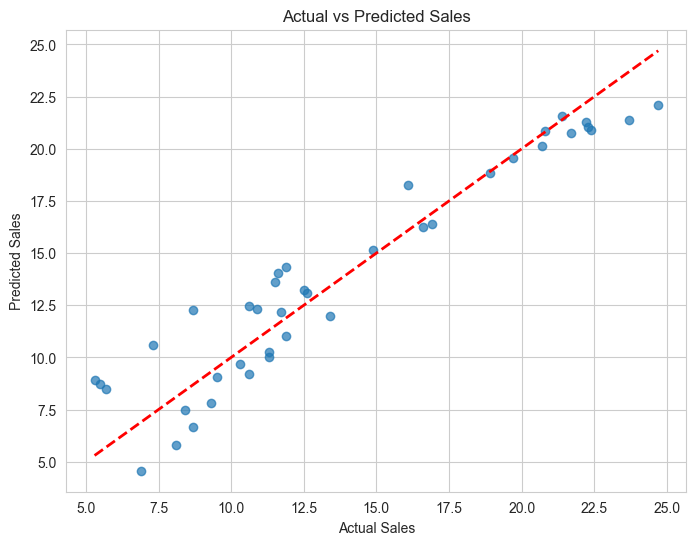

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.grid(True)

plt.show()

In [10]:
new_data = pd.DataFrame({
    'TV': [200, 150, 100],
    'radio': [40, 30, 20],
    'newspaper': [50, 40, 30]
})

predicted_sales = model.predict(new_data)

new_data['Predicted Sales'] = predicted_sales

print("Sales Prediction for New Advertising Data:")
display(new_data)

Sales Prediction for New Advertising Data:


,TV,radio,newspaper,Predicted Sales
0,200,40,50,19.630829
1,150,30,40,15.474791
2,100,20,30,11.318754
